# Monte Carlo Analysis and Python-based Simulations

**Social Science Simulations (SVUH.00.300): Seminar**
Kishor Acharya · Institute of Social Studies, University of Tartu · Autumn 2026

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ACHARYAkishor/Monte_carlo_Seminar_UniTartu/blob/main/Monte_Carlo_UniTartu_ACHARYA.ipynb)  ·  [Slides and source on GitHub](https://github.com/ACHARYAkishor/Monte_carlo_Seminar_UniTartu)

---

## How to use this notebook

This notebook follows the seminar slides stop by stop and uses the same numbering, so you can keep it open next to the lecture. It assumes **no previous knowledge of Python, probability or statistics**. Every section has:

* a short explanation in plain words (cells like this one),
* a code cell you run (click into it and press **Shift + Enter**, or the ▶ button on the left),
* a **▶ Try it** cell with sliders, so you can change the numbers without touching the code,
* a **✎ Exercise** for later.

You do not need to understand every line of code to follow the seminar. Read the comments (the parts after `#`), run the cell, look at the picture. The code is there for those who want it.

> **First step:** run the setup cell below. It loads the tools we need and fixes the colours. Nothing else works until you do.
>
> **Don't see sliders in the ▶ Try it cells?** The notebook is meant to be run in Google Colab, where sliders work without any setup. In a local Jupyter you need a recent `ipywidgets` (`pip install -U ipywidgets`, then restart the kernel). If sliders still don't show, every Try it cell also works without them: change the number in the first line of the cell and run it again.

The interactive animations on the course website ([acharyakishor.com/simulations/monte-carlo](https://acharyakishor.com/simulations/monte-carlo)) show the same experiments without any code.

In [1]:
# ---- Setup: run this cell first ------------------------------------------
import numpy as np                      # numbers and random numbers
import matplotlib.pyplot as plt         # pictures
from scipy import stats                 # statistical tests (used at Stop 4)
from ipywidgets import interact, IntSlider, FloatSlider   # sliders

# A consistent look for all figures in this notebook
PURPLE, TEAL, CORAL, GRAY, AMBER = "#0A5C5C", "#1D9E75", "#D85A30", "#888780", "#C97B3A"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

# The random number generator. The seed makes the "random" numbers reproducible:
# everyone who runs this notebook with seed 42 sees exactly the same results.
rng = np.random.default_rng(seed=42)
print("Setup done. NumPy", np.__version__)

# Check that sliders can be displayed in this environment
import ipywidgets
from IPython.display import display
display(IntSlider(value=3, description="test slider"))
print("If you see a slider just above, you are ready. If you only see text like IntSlider(...),")
print("your notebook viewer lacks the widget front-end: open this notebook in Google Colab (link at the top),")
print("or run  !python -m pip install -U ipywidgets or %pip install -U ipywidgets (in notebook) and then restart the kernel. ipywidgets", ipywidgets.__version__)

<frozen importlib._bootstrap>:219: RuntimeWarning: scipy._lib.messagestream.MessageStream size changed, may indicate binary incompatibility. Expected 56 from C header, got 64 from PyObject


Setup done. NumPy 1.24.3


IntSlider(value=3, description='test slider')

If you see a slider just above, you are ready. If you only see text like IntSlider(...),
your notebook viewer lacks the widget front-end: open this notebook in Google Colab (link at the top),
or run  !python -m pip install -U ipywidgets or %pip install -U ipywidgets (in notebook) and then restart the kernel. ipywidgets 8.1.9


# Part A · Building blocks

Before the method itself, four ideas it rests on. Each one gets a picture.

## A.1 Probability is a long-run share

When we say "the probability of heads is one half" we mean something very concrete: **if you flipped the coin an enormous number of times, about half the flips would be heads.** Probability is the share of times something happens in the long run.

The cell below flips a simulated coin and plots the running share of heads. Early on the share wanders; later it settles. *Probability is where the line settles.*

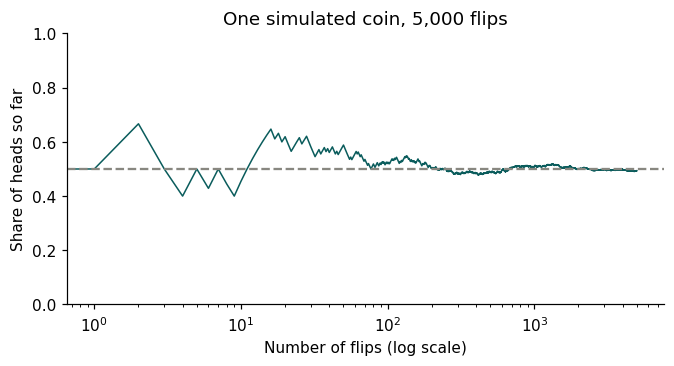

In [3]:
flips = rng.integers(0, 2, size=5000)            # 5,000 flips: 0 = tails, 1 = heads
running_share = np.cumsum(flips) / np.arange(1, 5001)   # share of heads after each flip

plt.plot(running_share, color=PURPLE, lw=1)
plt.axhline(0.5, color=GRAY, ls="--")
plt.xscale("log"); plt.ylim(0, 1)
plt.xlabel("Number of flips (log scale)"); plt.ylabel("Share of heads so far")
plt.title("One simulated coin, 5,000 flips");

**This is the whole secret of Monte Carlo.** If probability is a long-run share, we can *measure* a probability by running the experiment many times and taking the share. We do not need a formula; we need patience, which a computer has in unlimited supply.

### ▶ Try it
Drag the slider to change how many flips you look at. Notice how wide the swings are at 20 flips and how narrow at 5,000.

In [4]:
@interact(flips_to_show=IntSlider(value=50, min=10, max=5000, step=10, description="Flips"))
def coin(flips_to_show):
    f = rng.integers(0, 2, size=flips_to_show)
    share = np.cumsum(f) / np.arange(1, flips_to_show + 1)
    plt.plot(share, color=PURPLE); plt.axhline(0.5, color=GRAY, ls="--")
    plt.ylim(0, 1); plt.xlabel("Flip number"); plt.ylabel("Share of heads so far")
    plt.title(f"After {flips_to_show} flips the share of heads is {share[-1]:.3f}")

interactive(children=(IntSlider(value=50, description='Flips', max=5000, min=10, step=10), Output()), _dom_cla…

## A.2 Random numbers from a computer

Every Monte Carlo simulation needs a source of randomness. Two practical facts:

1. **Computers give pseudo-random numbers.** They run a formula whose output passes every test of randomness. For our purposes that is random enough.
2. **The sequence starts from a seed.** Same seed, same "random" numbers, every time. This is a feature: it lets you and your colleagues reproduce the same simulation exactly.

| What you want | Excel | Python (this notebook) |
|---|---|---|
| a number between 0 and 1, all equally likely | `=RAND()` | `rng.random()` |
| a whole number between 1 and 6 (a die) | `=RANDBETWEEN(1,6)` | `rng.integers(1, 7)` |
| a bell-curve number, mean 100, SD 10 | `=NORMINV(RAND(),100,10)` | `rng.normal(100, 10)` |

In [5]:
print("One number between 0 and 1:  ", rng.random())
print("Five dice rolls:             ", rng.integers(1, 7, size=5))
print("Three bell-curve numbers:    ", rng.normal(100, 10, size=3).round(1))

# Same seed -> same numbers. Run this cell twice: the two lines below never change.
a = np.random.default_rng(seed=7).random(3)
b = np.random.default_rng(seed=7).random(3)
print("Seed 7, first time: ", a.round(4))
print("Seed 7, second time:", b.round(4))

One number between 0 and 1:   0.7391322445864148
Five dice rolls:              [1 2 1 2 4]
Three bell-curve numbers:     [94.8 94.4 95.3]
Seed 7, first time:  [0.6251 0.8972 0.7757]
Seed 7, second time: [0.6251 0.8972 0.7757]


## A.3 Distributions: the shape of uncertainty

A **distribution** describes which values a random quantity can take and how often it takes them. The easiest way to *see* a distribution is to draw many values and make a **histogram**: a bar chart of how many draws fell into each interval.

Two distributions do almost all the work in this seminar:

* **Uniform** — every value in a range is equally likely. What the computer gives by default. Right for "a dart thrown at random onto a square".
* **Normal (the bell curve)** — values cluster around a central value (the **mean**) and become rarer further away. How fast they become rarer is set by the **standard deviation (SD)**. About 68% of draws fall within 1 SD of the mean, 95% within 2 SD, 99.7% within 3 SD. Right for measurement error and for the error of an opinion poll.

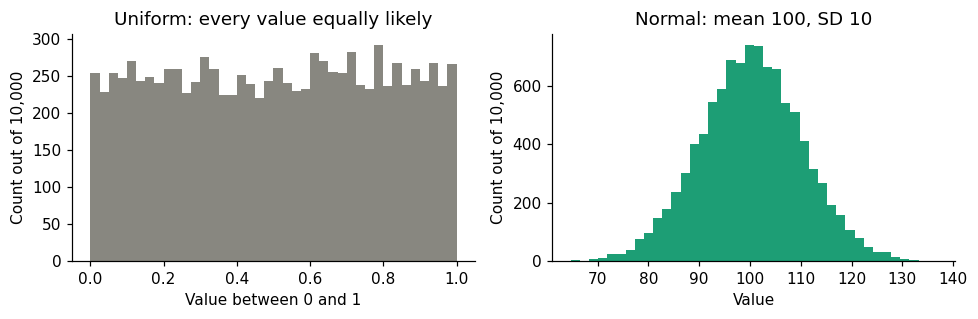

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(rng.uniform(0, 1, 10000), bins=40, color=GRAY)
ax[0].set_title("Uniform: every value equally likely"); ax[0].set_xlabel("Value between 0 and 1")
ax[1].hist(rng.normal(100, 10, 10000), bins=40, color=TEAL)
ax[1].set_title("Normal: mean 100, SD 10"); ax[1].set_xlabel("Value")
for a in ax: a.set_ylabel("Count out of 10,000")
plt.tight_layout()

### ▶ Try it
Move the mean and the SD. The mean slides the bell; the SD widens or narrows it. Watch the shaded "within 2 SD" band: it always holds about 95% of the draws.

In [7]:
@interact(mean=FloatSlider(value=100, min=50, max=150, step=5, description="Mean"),
          sd=FloatSlider(value=10, min=1, max=30, step=1, description="SD"))
def bell(mean, sd):
    x = rng.normal(mean, sd, 10000)
    plt.hist(x, bins=50, range=(0, 200), color=TEAL)
    plt.axvspan(mean - 2*sd, mean + 2*sd, color=AMBER, alpha=0.2)
    inside = np.mean((x > mean - 2*sd) & (x < mean + 2*sd))
    plt.title(f"{inside*100:.1f}% of draws lie within 2 SD of the mean")
    plt.xlabel("Value"); plt.ylabel("Count")

interactive(children=(FloatSlider(value=100.0, description='Mean', max=150.0, min=50.0, step=5.0), FloatSlider…

## A.4 The law of large numbers, and the 1/√N rule

That the running share in A.1 *always* settles, for any repeated random experiment, is the **law of large numbers** (Jacob Bernoulli, published 1713). It is the guarantee that Monte Carlo works at all: the average of many simulated outcomes converges to the true value.

It also tells us **how fast**. The typical error of a Monte Carlo estimate shrinks in proportion to **1/√N**, one over the square root of the number of runs. In words: *to make the error ten times smaller you need a hundred times more runs.* Ten thousand runs give you roughly two decimal places; a million give three.

We will see this as a straight line on a log-log plot at Stop 1. Remember the consequence: **a Monte Carlo result must always be reported together with its spread.**

# Part B · The recipe

> **Monte Carlo answers a question by generating many random versions of the situation and counting what happens.**

Every Monte Carlo simulation, from dice to climate models, has the same **three ingredients**:

1. a **model** of the situation with something uncertain in it (a die, a dart's landing point, the error of a poll, a person's decision);
2. a **random number generator** that draws one concrete version of each uncertain thing;
3. **repetition and aggregation**: thousands of draws, then count, average or make a histogram.

and follows the same **four steps**:

1. Define the output you care about (a yes/no event, a number, a whole curve).
2. Describe each uncertain input by a distribution.
3. Draw one value for every input, run the model once, record the output. Repeat N times.
4. Summarise the N recorded outputs, together with their uncertainty.

That is the whole method. The rest of the notebook climbs through five progressively richer uses of this recipe.

# Stop 1 · Two dice, and the first Monte Carlo

**Question:** roll two ordinary dice and add them. What is the probability that the sum is 7?

We can answer this exactly, which is why it is a good first example: we can check the simulation against the truth. There are 6 × 6 = 36 equally likely pairs of faces, and six of them add to 7 (1+6, 2+5, 3+4, 4+3, 5+2, 6+1), so the probability is 6/36 = 1/6 ≈ 16.7%.

## 1.1 The Monte Carlo answer in four lines

The simulation does not know any of that. It rolls, adds, and counts.

In [8]:
N = 10_000                                               # how many times we roll
sums = rng.integers(1, 7, N) + rng.integers(1, 7, N)    # N rolls of two dice, added
estimate = np.mean(sums == 7)                            # share of rolls whose sum is 7

print(f"Monte Carlo estimate of P(sum = 7): {estimate:.4f}")
print(f"Exact value:                        {1/6:.4f}")

Monte Carlo estimate of P(sum = 7): 0.1595
Exact value:                        0.1667


Run the cell above a few times (Shift + Enter again). The estimate changes slightly each time: **the estimate is itself random.** That is normal, and it is why we report a spread.

## 1.2 The whole distribution of the sum

Instead of one probability, look at all of them at once: a histogram of the sum, with the exact probabilities as dots.

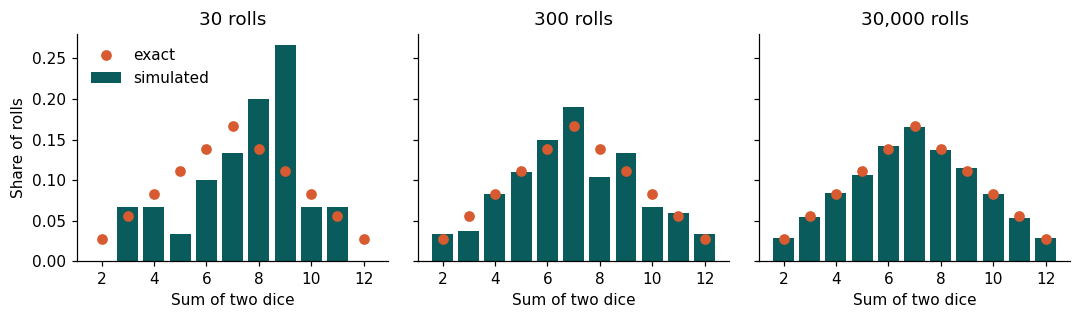

In [9]:
exact = np.array([0, 0, 1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]) / 36     # exact P(sum) for sums 0..12

fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, n in zip(axes, [30, 300, 30_000]):
    s = rng.integers(1, 7, n) + rng.integers(1, 7, n)
    share = np.bincount(s, minlength=13) / n                  # share of rolls giving each sum
    ax.bar(range(2, 13), share[2:], color=PURPLE, label="simulated")
    ax.plot(range(2, 13), exact[2:], "o", color=CORAL, label="exact")
    ax.set_title(f"{n:,} rolls"); ax.set_xlabel("Sum of two dice")
axes[0].set_ylabel("Share of rolls"); axes[0].legend(frameon=False)
plt.tight_layout()

### ▶ Try it
Drag the slider from 10 rolls to 100,000. At 10 the picture is noise; at 100 the triangle is there; at 100,000 the bars sit on the dots. You are watching the law of large numbers. The title reuses the same rolls that drew the bars: P(7) is simply the height of the middle bar.

In [10]:
@interact(rolls=IntSlider(value=100, min=10, max=100_000, step=10, description="Rolls"))
def dice(rolls):
    s = rng.integers(1, 7, rolls) + rng.integers(1, 7, rolls)
    share = np.bincount(s, minlength=13) / rolls
    plt.bar(range(2, 13), share[2:], color=PURPLE)
    plt.plot(range(2, 13), exact[2:], "o", color=CORAL)
    plt.xlabel("Sum of two dice"); plt.ylabel("Share of rolls")
    plt.title(f"{rolls:,} rolls:  P(7) estimated {share[7]:.3f}, exact {1/6:.3f}, error {abs(share[7]-1/6):.3f}")

interactive(children=(IntSlider(value=100, description='Rolls', max=100000, min=10, step=10), Output()), _dom_…

## 1.3 The error shrinks like 1/√N

For each number of rolls N we repeat the whole estimate 20 times and record how much the 20 estimates scatter (their standard deviation). On log-log axes the points fall on a straight line of slope −½: every hundredfold increase in N buys a tenfold reduction in scatter.

Be clear about what is shrinking. The probability itself, 1/6, does not change with N. What shrinks is the *scatter of our estimate around it*. The dashed line is the theoretical value of that scatter, √(p(1−p)/N) ≈ 0.37/√N with p = 1/6; statisticians call it the **standard error**.

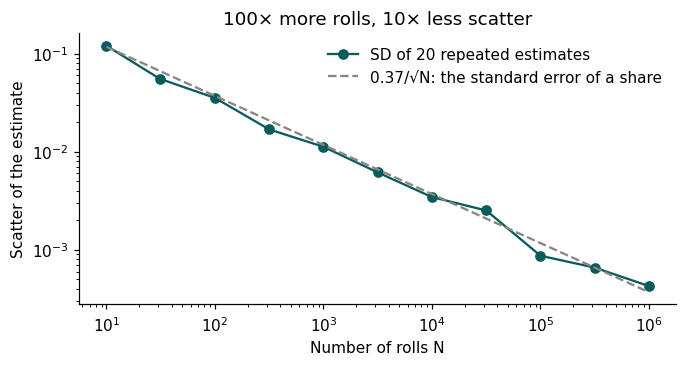

In [11]:
Ns = np.logspace(1, 6, 11).astype(int)       # 10, 30, 100, ..., 1,000,000
scatter = []
for n in Ns:
    estimates = []
    for repeat in range(20):                               # 20 independent estimates at this N
        s = rng.integers(1, 7, n) + rng.integers(1, 7, n)
        estimates.append(np.mean(s == 7))
    scatter.append(np.std(estimates))                      # how much they disagree: their SD

plt.loglog(Ns, scatter, "o-", color=PURPLE, label="SD of 20 repeated estimates")
plt.loglog(Ns, 0.37 / np.sqrt(Ns), "--", color=GRAY, label="0.37/√N: the standard error of a share")
plt.xlabel("Number of rolls N"); plt.ylabel("Scatter of the estimate"); plt.legend(frameon=False)
plt.title("100× more rolls, 10× less scatter");

> **What we learned at Stop 1**
> * A probability can be measured by counting, without any formula.
> * The estimate is itself random: run it twice and you get two slightly different numbers.
> * More runs give a better estimate, with diminishing returns (1/√N).


**Where is the Monte Carlo here?**

| | |
|---|---|
| The model | Two dice, added together. Everything else about the world is ignored. |
| The random draw | One roll: two random whole numbers from 1 to 6. |
| Repeat and count | Roll N times; count how often the sum is 7; divide by N. That share is the estimate of the probability. |

*What this stop adds to the argument:* the recipe (model, random draws, repeat, count) in its simplest form, with a known answer to check it against. From here on the recipe never changes; only what sits inside the model does.

### ✎ Exercise 1
Change the code in 1.1 to estimate the probability that the **two dice show the same number** (a "double"). The exact answer is 6/36 = 1/6 again. Hint: draw the two dice separately, `d1 = rng.integers(1, 7, N)` and `d2 = ...`, then count `d1 == d2`.

# Stop 2 · Darts, π, and measuring with randomness

At Stop 1 the output was a probability. Now we use the same trick to measure a number that has nothing to do with chance: **π**.

Imagine a square dartboard with sides of length 1, and inside it a quarter of a circle of radius 1 drawn from one corner. The area of the square is 1; the area of the quarter circle is π/4 ≈ 0.785. Throw darts at the board **completely at random**. The share of darts landing inside the quarter circle (inside ÷ thrown) will, in the long run, equal its share of the area. So the share *estimates the area*, π/4 ≈ 0.785; and the formula for the area of a circle is what turns that area into π: multiply by 4. So

$$\pi \approx 4 \times \frac{\text{darts inside}}{\text{darts thrown}}$$

Nobody is gambling here. We are using randomness as a **ruler**.

## 2.1 Throw the darts

In [12]:
N = 100_000
x = rng.random(N)                  # dart's horizontal position, 0 to 1
y = rng.random(N)                  # dart's vertical position, 0 to 1
inside = x**2 + y**2 <= 1          # True if the dart is inside the quarter circle
pi_estimate = 4 * np.mean(inside)

print(f"Darts thrown: {N:,}   inside: {inside.sum():,}")
print(f"Estimate of π: {pi_estimate:.4f}   (true value {np.pi:.4f})")

Darts thrown: 100,000   inside: 78,668
Estimate of π: 3.1467   (true value 3.1416)


## 2.2 See the board, and watch the estimate settle

Left: the first 3,000 darts. Right: the running estimate as darts accumulate. It is wildly wrong at first, swings less and less, and after 100,000 darts is within a few thousandths of π. **It never becomes exact**, and if you ran it again the path would differ. A Monte Carlo estimate should always be quoted with a margin: here, roughly "3.14 ± 0.01".

Where does the ± 0.01 come from? Two kinds of error must be kept apart.

* The **actual error** is |estimate − π|. We can only compute it because we happen to know π. In a real problem we never know the answer, otherwise we would not be simulating.
* The **standard error** is the scatter we expect from the data alone, and it is always available. The share inside is a share with p ≈ 0.785, so its standard error is √(p(1−p)/N) = √(0.785 × 0.215 / 100,000) ≈ 0.0013. We multiplied the share by 4, so the standard error of π is about 0.005. Two standard errors, the usual margin, give about 0.01.

That is the number to report, and it needed no knowledge of π. The cell below prints both.

Estimate 3.1467 ± 0.0104 (two standard errors)
Actual error, which we can see only because we know π: 0.0051


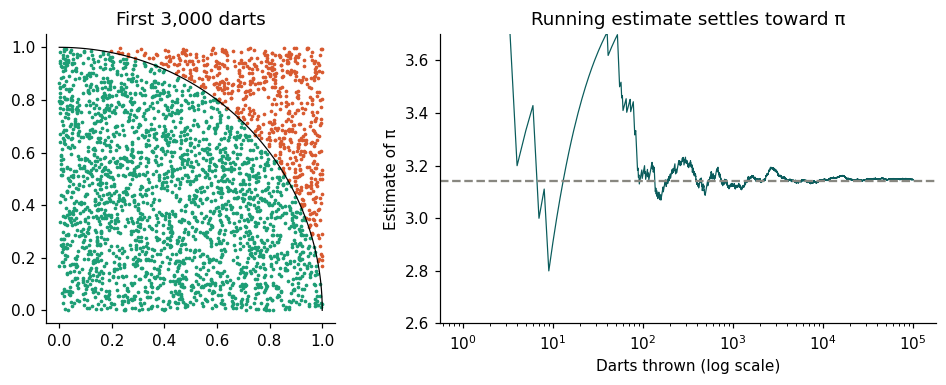

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
k = 3000
ax[0].scatter(x[:k][inside[:k]], y[:k][inside[:k]], s=2, color=TEAL)
ax[0].scatter(x[:k][~inside[:k]], y[:k][~inside[:k]], s=2, color=CORAL)
t = np.linspace(0, np.pi/2, 100); ax[0].plot(np.cos(t), np.sin(t), color="black", lw=0.8)
ax[0].set_aspect("equal"); ax[0].set_title(f"First {k:,} darts")

running = 4 * np.cumsum(inside) / np.arange(1, N + 1)
ax[1].plot(running, color=PURPLE, lw=0.8); ax[1].axhline(np.pi, color=GRAY, ls="--")
ax[1].set_xscale("log"); ax[1].set_ylim(2.6, 3.7)
ax[1].set_xlabel("Darts thrown (log scale)"); ax[1].set_ylabel("Estimate of π")
ax[1].set_title("Running estimate settles toward π")
plt.tight_layout()

share = np.mean(inside)
standard_error = 4 * np.sqrt(share * (1 - share) / N)     # from the data only
print(f"Estimate {pi_estimate:.4f} ± {2*standard_error:.4f} (two standard errors)")
print(f"Actual error, which we can see only because we know π: {abs(pi_estimate - np.pi):.4f}")

### ▶ Try it

In [14]:
@interact(darts=IntSlider(value=1000, min=10, max=50_000, step=10, description="Darts"))
def pi_darts(darts):
    x = rng.random(darts); y = rng.random(darts); inside = x**2 + y**2 <= 1
    plt.figure(figsize=(3.6, 3.6))
    plt.scatter(x[inside], y[inside], s=3, color=TEAL); plt.scatter(x[~inside], y[~inside], s=3, color=CORAL)
    plt.gca().set_aspect("equal")
    plt.title(f"π ≈ 4 × {inside.sum()}/{darts} = {4*inside.mean():.4f}   (error {abs(4*inside.mean()-np.pi):.4f})")

interactive(children=(IntSlider(value=1000, description='Darts', max=50000, min=10, step=10), Output()), _dom_…

## 2.3 The same idea finds any area (Monte Carlo integration)

Nothing about the method depends on the shape being a circle. Replace the quarter circle by *the region under any curve* and the same count gives the area under that curve, which mathematicians call its **integral**. Below we do it for y = x² between 0 and 1, whose exact area is 1/3.

Change the function `f` to any curve you like (for example `np.sin(x)`, or `x**3`) and run again.

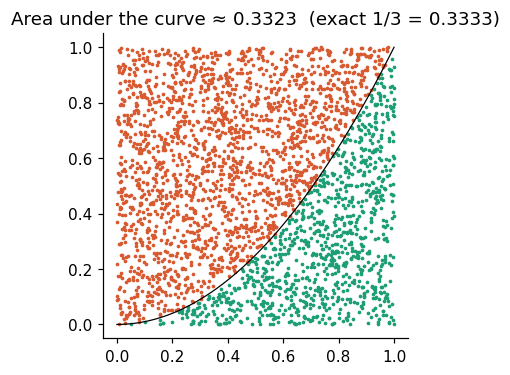

In [19]:
def f(x):
    return x**2                     # <-- change this to any curve between 0 and 1

N = 20_000
x = rng.random(N); y = rng.random(N)
under = y <= f(x)                                 # True if the point is under the curve
area_estimate = np.mean(under)                    # share of points under the curve = area

plt.figure(figsize=(3.8, 3.6))
plt.scatter(x[:3000][under[:3000]], y[:3000][under[:3000]], s=2, color=TEAL)
plt.scatter(x[:3000][~under[:3000]], y[:3000][~under[:3000]], s=2, color=CORAL)
xs = np.linspace(0, 1, 200); plt.plot(xs, f(xs), color="black", lw=0.8)
plt.gca().set_aspect("equal")
plt.title(f"Area under the curve ≈ {area_estimate:.4f}  (exact 1/3 = {1/3:.4f})");

For one curve a calculator does better. The method comes into its own when the "area" lives in ten or a hundred dimensions, where ordinary numerical methods become impossibly slow but random sampling costs the same regardless of dimension. That is why Monte Carlo integration is a standard tool in physics, in Bayesian statistics and in economics.

**A piece of history.** In 1777 the Comte de Buffon showed that if you drop a needle on a floor of parallel boards, the probability that it crosses a crack depends on π. Dropping many needles and counting the crossings is the first Monte Carlo experiment on record, done by hand. The cell below repeats it with a simulated needle.

In [ ]:
# Buffon's needle: boards of width 1, needle of length 1. P(crossing) = 2/π.
N = 100_000
centre = rng.random(N)                      # distance of needle's centre from the crack below (0 to 1)
angle = rng.random(N) * np.pi               # needle's angle (0 to 180 degrees)
crosses = (centre <= 0.5 * np.sin(angle)) | (1 - centre <= 0.5 * np.sin(angle))
print(f"Share crossing: {crosses.mean():.4f}  ->  π ≈ 2 / share = {2 / crosses.mean():.4f}")

> **What we learned at Stop 2**
> * Monte Carlo can estimate numbers, not just probabilities, by turning a measurement into a count.
> * The running estimate converges but never becomes exact: always report a margin.
> * The method does not care how many dimensions the problem has. That is its great advantage.


**Where is the Monte Carlo here?**

| | |
|---|---|
| The model | A square board with a quarter circle drawn inside it. No chance is involved in the question itself. |
| The random draw | One dart: a random point in the square, two random numbers between 0 and 1. |
| Repeat and count | Throw N darts; count the share inside the circle. That share estimates an area; multiplying by 4 turns the area into π. |

*What this stop adds to the argument:* the same recipe, but the thing we count now measures a number rather than a chance, and we learn to attach a margin to it from the data alone.

### ✎ Exercise 2
In 2.1, how many darts do you need before the estimate of π is reliably within 0.01 of the truth? Try N = 1,000, 10,000, 100,000 and run each several times. Does the 1/√N rule predict what you see?

# Stop 3 · A referendum, and taming the future

Stops 1 and 2 estimated things we could have calculated. From here on, Monte Carlo does things we cannot easily do any other way. The first: take a model with **several uncertain inputs** and produce not a single "best guess" but **the full range of outcomes, with the probability of each**.

**The situation.** Polls say 52% will vote *yes*. But polls have error: historically the final result differs from the last polls by about **3 percentage points** either way. Turnout is uncertain too: based on past elections, the *yes* side tends to turn out slightly less, costing it about **1 point, give or take 1**. Will the proposal pass?

A single number cannot answer this. 52 − 1 = 51, "yes, narrowly", ignores the ±3 and the ±1. The honest answer is a **probability**, and Monte Carlo produces it by simulating ten thousand election nights, each with its own random poll error and its own random turnout effect.

## 3.1 Ten thousand election nights

In [2]:
N = 10_000
poll_says     = 52
poll_error    = rng.normal(0, 3, N)       # the polls miss by about 3 points (bell curve, SD 3)
turnout_tilt  = rng.normal(-1, 1, N)      # turnout costs "yes" about 1 point (mean -1, SD 1)

result = poll_says + poll_error + turnout_tilt      # the final yes-share in each simulated election

p_pass = np.mean(result > 50)
low, high = np.percentile(result, [5, 95])
print(f"Probability that yes wins:  {p_pass:.1%}")
print(f"Median result:              {np.median(result):.1f}% yes")
print(f"90% of outcomes lie between {low:.1f}% and {high:.1f}% yes")

Probability that yes wins:  62.4%
Median result:              51.0% yes
90% of outcomes lie between 45.8% and 56.2% yes


## 3.2 The histogram is the deliverable

It says three things the number 52 could not: the proposal will *probably* pass; there is a *real chance* that it fails; and almost any result between 46% and 56% would be unsurprising.

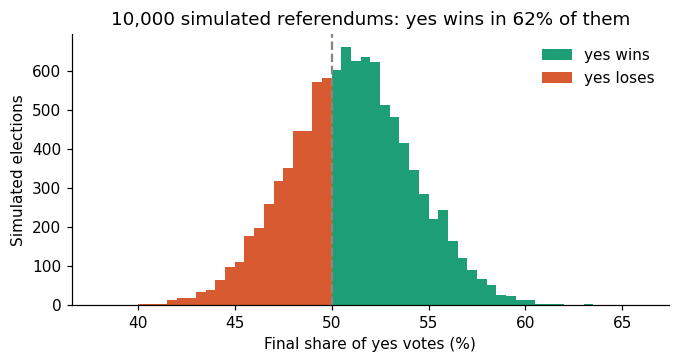

In [3]:
bins = np.linspace(38, 66, 57)
counts, edges = np.histogram(result, bins)
mid = (edges[:-1] + edges[1:]) / 2
plt.bar(mid[mid > 50], counts[mid > 50], width=0.5, color=TEAL, label="yes wins")
plt.bar(mid[mid <= 50], counts[mid <= 50], width=0.5, color=CORAL, label="yes loses")
plt.axvline(50, color=GRAY, ls="--")
plt.xlabel("Final share of yes votes (%)"); plt.ylabel("Simulated elections")
plt.title(f"10,000 simulated referendums: yes wins in {p_pass:.0%} of them"); plt.legend(frameon=False);

### ▶ Try it
Move the poll mean toward 50 and watch the probability fall. Widen the poll error and watch the histogram flatten. Find the poll lead at which the pass probability reaches 90%.

In [22]:
@interact(poll=FloatSlider(value=52, min=45, max=60, step=0.5, description="Polled yes %"),
          poll_sd=FloatSlider(value=3, min=0.5, max=8, step=0.5, description="Poll error ±"),
          tilt=FloatSlider(value=-1, min=-3, max=3, step=0.5, description="Turnout tilt"))
def referendum(poll, poll_sd, tilt):
    r = poll + rng.normal(0, poll_sd, 10_000) + rng.normal(tilt, 1, 10_000)
    counts, edges = np.histogram(r, np.linspace(30, 70, 81)); mid = (edges[:-1] + edges[1:]) / 2
    plt.bar(mid[mid > 50], counts[mid > 50], width=0.5, color=TEAL)
    plt.bar(mid[mid <= 50], counts[mid <= 50], width=0.5, color=CORAL)
    plt.axvline(50, color=GRAY, ls="--"); plt.xlabel("Final yes share (%)"); plt.ylabel("Simulated elections")
    lo, hi = np.percentile(r, [5, 95])
    plt.title(f"P(yes wins) = {np.mean(r > 50):.1%}    90% of outcomes: {lo:.1f}% – {hi:.1f}%")

interactive(children=(FloatSlider(value=52.0, description='Polled yes %', max=60.0, min=45.0, step=0.5), Float…

This use of Monte Carlo — distributions in, a distribution out — is the one you will meet most often outside the classroom. It is how project managers estimate the chance of finishing on time, how engineers estimate the risk of failure, how insurers price a policy, and how epidemiologists project an outbreak. Verschuuren (2017) calls it *taming the future*: not predicting it, but mapping how wide it is.

> **What we learned at Stop 3**
> * Replace every fixed input by a distribution; the output becomes a distribution too.
> * Summarise it as a probability, a median, and a range (for example the 5th to 95th percentile).
> * The histogram is more honest, and more useful, than any single number.


**Where is the Monte Carlo here?**

| | |
|---|---|
| The model | An election night: final yes-share = polled share + poll error + turnout effect. Three inputs, two of them uncertain. |
| The random draw | One election: a random poll error (bell curve, SD 3) and a random turnout effect (bell curve, mean −1, SD 1). |
| Repeat and count | Play N election nights and keep every result. The share above 50% is the probability of passing; sorting gives the median and the 5–95% range; all of them together are the histogram. |

*What this stop adds to the argument:* the model inside the recipe now has several uncertain inputs at once, and the output we keep is the whole distribution, not one number.

### ✎ Exercise 3 — a fieldwork budget
A survey project has three cost items, each uncertain: interviewers (mean €6,000, SD €800), travel (mean €2,000, SD €500) and transcription (mean €3,000, SD €1,000). You have a budget of €12,000. Simulate 10,000 projects (one `rng.normal(...)` per item, add them) and find the probability that the total exceeds the budget. The skeleton is below.

In [4]:
N = 10_000
interviewers  = rng.normal(6000, 800, N)
travel        = rng.normal(2000, 500, N)
transcription = rng.normal(3000, 1000, N)
total = interviewers + travel + transcription

print(f"Probability of exceeding €12,000: {np.mean(total > 12_000):.1%}")
print(f"90% of projects cost between €{np.percentile(total, 5):,.0f} and €{np.percentile(total, 95):,.0f}")
# Your turn: plot a histogram of `total`, and find the budget that would be safe 95% of the time.

Probability of exceeding €12,000: 23.3%
90% of projects cost between €8,709 and €13,273


# Stop 4 · Planning a survey by simulating fake data

The next capability is less obvious but, for anyone who will design a study, probably the most useful. Monte Carlo lets you **test a research design before collecting a single real observation**, by simulating data in a world where you know the truth and checking whether your analysis finds it.

**The situation.** You plan to compare two groups of people on some attitude measured by a questionnaire. You expect a modest difference. How many people do you need in each group to have a good chance of detecting that difference, *if it is really there*?

Statisticians call this chance the **power** of the study. One study gives one yes or no: it detects the difference or it does not. Power is the share of *whole studies*, across many imagined repeats of the same design, that would detect it. The usual target is 80%. The Monte Carlo approach:

1. Invent a world in which the difference is real, of a given size.
2. Simulate one fake study in that world: draw a sample from each group, run your statistical test, note whether it "detects" the difference (p < 0.05).
3. Repeat a thousand times. The share of fake studies that detected the effect is the power.
4. Change the sample size and repeat, until the power reaches 80%.

**The one input you must assume: the effect size.** It is the difference between the two group means divided by the standard deviation of the measurement:

$$d = \frac{\text{mean of group B} - \text{mean of group A}}{\text{SD}}$$

Why divide by the SD? Because a raw difference means nothing without the spread. On a 1-to-5 agreement scale, a difference of 0.5 points between two municipalities is large if almost everyone answers 3 or 4 (SD about 0.6) and small if answers are spread over the whole scale (SD about 1.4). Dividing by the SD puts every measurement on the same footing. Cohen's (1988) conventions: d = 0.2 is small (the two groups' bell curves overlap almost completely; you would not see the difference by eye), 0.5 is medium (visible overlap but clearly shifted), 0.8 is large (the shift is obvious in a histogram). You have to decide *before* simulating what size of effect you care about detecting; the simulation cannot tell you that.

## 4.1 Power as a function

In [5]:
def power(n_per_group, effect_size, reps=1000):
    '''Share of simulated two-group studies that find a real effect of the given size.'''
    detections = 0
    for _ in range(reps):
        group_a = rng.normal(0, 1, n_per_group)              # the invented world: group A centred on 0, SD 1
        group_b = rng.normal(effect_size, 1, n_per_group)    # ... and group B shifted by exactly d. THIS LINE IS THE TRUTH WE WROTE.
        p_value = stats.ttest_ind(group_a, group_b).pvalue   # the usual t-test
        if p_value < 0.05:
            detections += 1
    return detections / reps

print(f"Medium effect, 30 per group:  power = {power(30, 0.5):.2f}   (too small a study)")
print(f"Medium effect, 64 per group:  power = {power(64, 0.5):.2f}   (just enough)")

Medium effect, 30 per group:  power = 0.45   (too small a study)
Medium effect, 64 per group:  power = 0.81   (just enough)


Read the line marked THE TRUTH WE WROTE. In this invented world the difference between the groups is real and exactly `effect_size`, because we put it there. So whenever the t-test fails to detect it, that is a *known* mistake, and counting those mistakes is what the function does. This is the whole point of simulating fake data: in the real world you never know whether a non-significant result is a miss or a true absence; in the invented world you always do.

The same machine can be used in three ways: vary the sample size for a fixed effect (how many people do I need?), vary the effect size for a fixed sample (what is the smallest effect my study can see?), or check one fixed design (I have 40 per group and expect d = 0.4: what are my chances?).

## 4.2 The power curve

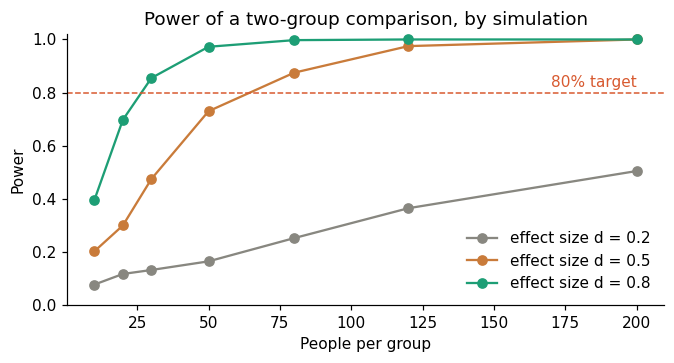

In [6]:
sizes = [10, 20, 30, 50, 80, 120, 200]
for d, colour in [(0.2, GRAY), (0.5, AMBER), (0.8, TEAL)]:
    plt.plot(sizes, [power(n, d, reps=400) for n in sizes], "o-", color=colour, label=f"effect size d = {d}")
plt.axhline(0.8, color=CORAL, ls="--", lw=1); plt.text(200, 0.82, "80% target", color=CORAL, ha="right")
plt.xlabel("People per group"); plt.ylabel("Power"); plt.ylim(0, 1.02); plt.legend(frameon=False)
plt.title("Power of a two-group comparison, by simulation");

**How to read the curve:** pick the line for your effect size, follow it until it crosses the dashed 80% line, and read the sample size off the horizontal axis. The medium line crosses at about 64 people per group. The small-effect line (d = 0.2) never reaches 80% on this plot; it gets there at about 400 per group, off the right edge. This is why underpowered studies of small effects are so common.

### ▶ Try it
Two things to try. Set the effect size to **0** (drag to the far left) and watch the power settle near 5%: with no real effect, one study in twenty still "detects" something. That 5% is the false-alarm rate α that the p < 0.05 rule allows. And notice that the bar jitters a little each time you move a slider: every move runs 400 fresh fake studies, so the power estimate is itself a Monte Carlo estimate with its own scatter.

In [9]:
@interact(n=IntSlider(value=30, min=5, max=300, step=5, description="Per group"),
          d=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="Effect size"))
def show_power(n, d):
    pw = power(n, d, reps=400)
    plt.figure(figsize=(6, 0.9)); plt.barh([0], [pw], color=TEAL if pw >= 0.8 else CORAL); plt.xlim(0, 1)
    plt.axvline(0.8, color=GRAY, ls="--"); plt.yticks([]); plt.xlabel("Power")
    plt.title(f"{n} per group, effect {d}:  power ≈ {pw:.0%}")

interactive(children=(IntSlider(value=30, description='Per group', max=300, min=5, step=5), FloatSlider(value=…

## 4.3 The same trick checks any method: does a 95% interval really cover 95%?

"Simulate a world where you know the truth" also answers: *does my confidence interval behave as advertised?* Below we draw 2,000 samples from a population whose mean we know (50), compute a 95% confidence interval for the mean from each sample, and count how often the interval contains the truth. It should be close to 95%.

In [10]:
true_mean, n, reps = 50, 25, 2000              # the truth we wrote: mean 50; samples of 25; 2,000 fake surveys
covered = 0
for _ in range(reps):
    sample = rng.normal(true_mean, 10, n)                       # one fake survey, SD 10
    t_value = stats.t.ppf(0.975, n - 1)                         # the multiplier for a 95% interval (about 2.06 for n = 25)
    half_width = t_value * sample.std(ddof=1) / np.sqrt(n)      # multiplier × standard error of the mean
    lower, upper = sample.mean() - half_width, sample.mean() + half_width
    if lower <= true_mean <= upper:                             # did this interval catch the truth?
        covered += 1
print(f"The 95% interval contained the true mean in {covered/reps:.1%} of {reps} samples.")

The 95% interval contained the true mean in 94.2% of 2000 samples.


> **What we learned at Stop 4**
> * You can test a study design by simulation before collecting any data.
> * Power is simply the share of simulated studies that find the real effect.
> * The same trick checks whether any statistical method behaves as advertised.


**Where is the Monte Carlo here?**

| | |
|---|---|
| The model | A whole study: two groups of n people, a score for each, and the test you would run on real data. The difference between the groups is set by you, so the truth is known. |
| The random draw | One fake study: n random scores for group A, n for group B shifted by the effect size, then the test, which answers yes or no. |
| Repeat and count | Run many fake studies; the share that answered yes is the power. At effect size 0 the same count gives the false-alarm rate. |

*What this stop adds to the argument:* the model inside the recipe is now a whole study, data and analysis included, and we simulate in a world where we wrote the truth ourselves so that every miss is a known mistake.

### ✎ Exercise 4
Your questionnaire has an unequal design: 40 people in group A but only 20 in group B. Modify `power()` to take two sample sizes and find the power for a medium effect. Then find how many people you would need in group B to reach 80% if group A stays at 40.

# Stop 5 · Schelling's neighbourhood, and Monte Carlo over an agent-based model

Now we connect Monte Carlo to the **agent-based models** of the previous lecture. The example is the most famous agent-based model in social science, proposed by Thomas Schelling (1971), and it will return in the next seminar.

## 5.1 The model

Picture a city as a grid of houses. Each house is either empty or occupied by a household of one of two kinds (purple or orange below; think of any social distinction you like). Every household has one preference: it wants **at least a certain share of its eight nearest neighbours to be of its own kind**. Call that share the household's **threshold**. A threshold of 0.30 means "at least 3 of my 8 neighbours should be like me" (3/8 = 0.375 is the first share above 0.30). A household whose neighbourhood falls below its threshold is *unhappy* and moves to a random empty house. Happy households stay. That is the entire model.

One warning about words. The sliders and plots call this number "tolerance", following common usage, but it points the wrong way: a *higher* value means a *more demanding* household, not a more tolerant one. In the text we say threshold.

We also need one number to describe the whole city. Our **segregation measure** is the average, over all households, of the share of their neighbours that are of their own kind. A perfectly mixed city scores about 0.5; a city split into two solid blocks scores close to 1.0.

Schelling's question: how strong does this preference have to be before the city segregates? The intuition most people have is that segregation requires strong prejudice. His result was that it does not: even when every household is content with as few as a third of its neighbours being like itself, a cascade of moves ends in large, nearly uniform clusters. **Mild individual preferences produce a strongly segregated collective outcome.** This gap between micro-motives and macro-behaviour is the central lesson of agent-based modelling.

The code below is the whole model. Note one design choice: the threshold (called `tolerance` in the code) is stored **per household** (an array), even though today every household gets the same value. In the next seminar we will draw those values from survey data, and only that one line will change.

In [2]:
EMPTY, A, B = 0, 1, 2

def new_city(size=30, empty_share=0.1, seed=0):
    '''A random city: each house is empty, or holds a household of kind A or B.'''
    r = np.random.default_rng(seed)
    return r.choice([EMPTY, A, B], size=(size, size),
                    p=[empty_share, (1 - empty_share) / 2, (1 - empty_share) / 2])

def share_similar(city):
    '''For every house: the share of its 8 neighbours that are the same kind as the occupant.'''
    size = city.shape[0]
    padded = np.pad(city, 1, mode="wrap")              # the grid wraps around at the edges
    same = np.zeros(city.shape); occupied = np.zeros(city.shape)
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            if dx == 0 and dy == 0:
                continue
            neighbour = padded[1 + dx: 1 + dx + size, 1 + dy: 1 + dy + size]
            same += (neighbour == city) & (neighbour != EMPTY)
            occupied += neighbour != EMPTY
    return np.where(occupied > 0, same / np.maximum(occupied, 1), 1.0)

def run_city(city, tolerance, steps=40, seed=0):
    '''Let unhappy households move until `steps` rounds have passed (or everyone is happy).
    `tolerance` is an array with one threshold per house (same value everywhere today).'''
    r = np.random.default_rng(seed)
    city = city.copy()
    for _ in range(steps):
        unhappy = (city != EMPTY) & (share_similar(city) < tolerance)
        movers = np.argwhere(unhappy); empties = np.argwhere(city == EMPTY)
        if len(movers) == 0:
            break
        r.shuffle(movers); r.shuffle(empties)
        for (i, j), (k, l) in zip(movers, empties):      # each mover takes a random empty house
            city[k, l], city[i, j] = city[i, j], EMPTY
    return city

def segregation(city):
    '''Our measure of segregation: the average share of similar neighbours, over all households.'''
    s = share_similar(city)
    return s[city != EMPTY].mean()

print("Model defined.")

Model defined.


## 5.2 One run

Left: the random starting city. Middle: after households with a 30% threshold have moved. Right: the same with a 50% threshold.

Look at the numbers under the middle picture. Every household stopped moving as soon as it had 30% similar neighbours, yet the city as a whole ends near 0.75. The households asked for a little and the city delivered a lot: that is Schelling's finding in two numbers.

**About the seed.** One seed is one complete random city: the random starting arrangement *and* the random order of moves. Change the seed and you get a different city that obeys the same rules. This is the same thing we did at every earlier stop: each roll of the dice, each dart and each fake survey was also a fresh random draw; the only difference is that a draw here is an entire city.

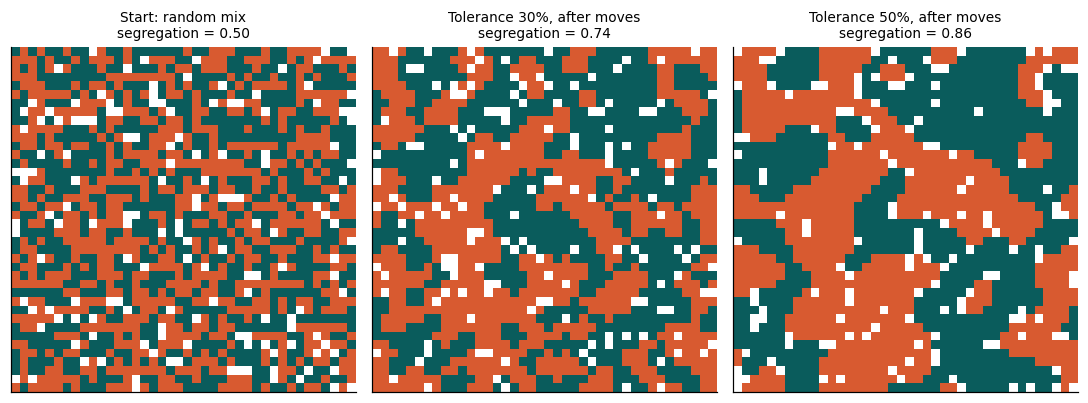

In [3]:
from matplotlib.colors import ListedColormap
city_colours = ListedColormap(["white", PURPLE, CORAL])

def show_city(city, title, ax):
    ax.imshow(city, cmap=city_colours, vmin=0, vmax=2, interpolation="nearest")
    ax.set_title(f"{title}\nsegregation = {segregation(city):.2f}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])

start = new_city(size=40, seed=1)
size = start.shape[0]
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
show_city(start, "Start: random mix", ax[0])
show_city(run_city(start, tolerance=np.full((size, size), 0.30), seed=1), "Tolerance 30%, after moves", ax[1])
show_city(run_city(start, tolerance=np.full((size, size), 0.50), seed=1), "Tolerance 50%, after moves", ax[2])
plt.tight_layout()

### ▶ Try it
This demo has two purposes, one per slider. The *tolerance* slider shows Schelling's finding: clusters appear already at a 30% threshold, a mild preference. The *seed* slider shows something about method: with the same threshold but a different seed the clusters land elsewhere and the segregation number differs. **Which run is "the result"? Neither.** A single run of a model with randomness in it is one draw from a distribution of possible outcomes, like one roll of the dice. It is an anecdote, and an anecdote is not evidence.

In [4]:
@interact(tolerance=FloatSlider(value=0.30, min=0.0, max=0.8, step=0.05, description="Tolerance"),
          seed=IntSlider(value=1, min=0, max=20, description="Seed"))
def schelling_once(tolerance, seed):
    start = new_city(size=30, seed=seed)
    end = run_city(start, tolerance=np.full(start.shape, tolerance), seed=seed)
    fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.2))
    show_city(start, "Start", ax[0]); show_city(end, f"Tolerance {tolerance:.0%}", ax[1])
    plt.tight_layout()

interactive(children=(FloatSlider(value=0.3, description='Tolerance', max=0.8, step=0.05), IntSlider(value=1, …

## 5.3 Many runs are an experiment

The remedy is the recipe from Part B. Treat the whole agent-based model as the *model* inside a Monte Carlo loop: fix the tolerance, run the city 20 times with 20 different seeds, record the final segregation each time. Then change the tolerance a little and do it again. (This cell takes a minute or so.)

In [ ]:
tolerances = np.arange(0.05, 0.76, 0.05)
runs_per_point = 20
results = np.zeros((len(tolerances), runs_per_point))

for i, tol in enumerate(tolerances):
    for seed in range(runs_per_point):
        start = new_city(size=30, seed=seed)
        end = run_city(start, tolerance=np.full(start.shape, tol), seed=seed)
        results[i, seed] = segregation(end)

average = results.mean(axis=1)
low, high = np.percentile(results, [5, 95], axis=1)

plt.plot(tolerances * 100, results[:, 7], "x", color=GRAY, label="one single run per tolerance (seed 7)")
plt.fill_between(tolerances * 100, low, high, color=PURPLE, alpha=0.2, label=f"90% band over {runs_per_point} runs")
plt.plot(tolerances * 100, average, "o-", color=PURPLE, label=f"average of {runs_per_point} runs")
plt.xlabel("Tolerance: minimum share of similar neighbours wanted (%)"); plt.ylabel("Segregation")
plt.title("Monte Carlo over an agent-based model: the segregation curve"); plt.legend(frameon=False, loc="lower right");

**How to read this plot as Monte Carlo.** The dots are the estimate (the average over 20 runs); the band is the spread (where 90% of single runs fell); the grey crosses are what one run per threshold would have told you, an anecdote at each point. Look at the code: the inner loop (`for seed in range(runs_per_point)`) is exactly the dice loop of Stop 1, with a city in place of a die. The outer loop over thresholds is the only new thing.

This curve is something no single run could show. It contains three findings:

* **A threshold.** Below about 25% tolerance the city stays mixed; between 25% and 30% segregation jumps sharply. With eight neighbours, that is the step from "I need two like me" to "I need three like me". Small changes in individual preference near this point make large changes in the city.
* **A surprise at the top.** Above roughly 65% segregation falls again. With a demand that extreme almost nobody can ever be satisfied, households keep moving, and the city never settles into clusters. You would not know that from one run.
* **A measure of confidence.** The band shows how much run-to-run variation to expect. Four hundred runs instead of twenty would tighten it by a factor of about four and a half (the 1/√N rule again).

> **The rule for every agent-based model you build in this course:** never report a single run. Run the model many times with different seeds, report the distribution of outcomes, and sweep the parameter you care about to find where the behaviour changes. That sweep is a Monte Carlo experiment. It is what turns a simulation from a story into evidence.


**Where is the Monte Carlo here?**

| | |
|---|---|
| The model | An agent-based model: a city of households, each with a threshold, moving by a simple rule. Each run has its own random start and random moves. |
| The random draw | One seed: one complete random city, start and moves together, run until it settles. A single run is one draw, as one roll was at Stop 1. |
| Repeat and count | At each threshold run the city with many seeds; the average segregation is the estimate, the 5–95% range is the band. The loop over seeds is the dice loop; the loop over thresholds is the only new thing. |

*What this stop adds to the argument:* the model inside the recipe is now a whole agent-based simulation, and the dice loop of Stop 1 wrapped around it is what turns anecdotes into a curve.

## 5.4 Looking ahead to the next seminar

Where did the number 30% come from? Nowhere. It stands in for an attitude that, in a real city, you would measure with a questionnaire item ("I would feel uncomfortable if most of my neighbours were different from me"), and then turn into a number. Different people would give different answers, so there is not one threshold but a *distribution* of thresholds. Turning qualitative attitudes into numbers (pseudo-quantification) and carrying the uncertainty of that translation into the model (quantification of uncertainty) is the subject of the next seminar.


### ✎ Exercise 5
Repeat the sweep of 5.3 with a **smaller city** (`size=15`). The band should become much wider. Why? Then try a larger `empty_share` (0.3 instead of 0.1): does the threshold move?

### Playground: Granovetter's threshold model
Mark Granovetter (1978) proposed a model of collective action in which each person joins a protest once at least a certain share of others has already joined. Each person's threshold is a pseudo-quantified attitude. The famous lesson: two crowds with the **same average** threshold can produce a full riot or nothing at all, depending on the **spread**. The cell below runs it. Keep the mean at 0.25 and move the SD slider slowly from 0.05 upward: at 0.10 almost nobody joins, and somewhere between 0.12 and 0.15 the final turnout flips from 0% to 100%, with the average attitude unchanged. This is why the next seminar replaces a single number by a distribution. (Both this model and a forest-fire model are also on the course website.)

**Granovetter's own example makes the mechanism plain.** Imagine 100 people whose thresholds are 0, 1, 2, 3, … up to 99 (each person needs one more than the last). The person with threshold 0 starts; that is one person, which is enough for the person with threshold 1; now two, enough for threshold 2; and so on until all 100 are in. Now change one person: replace the threshold 1 by 2. The starter still starts, but nobody needs exactly one other person any more, so the chain breaks at the first link and the crowd stays at one. Same crowd to within a single person, same average to within a hundredth, and a riot has become nothing. A cascade needs an unbroken ladder of thresholds; spread is what supplies the rungs. The cell below reproduces it; the one after it is the slider version with a random crowd.

In [6]:
def cascade_size(thresholds):
    '''How many people end up joining, given each person's threshold (a count of others needed).'''
    joined = 0
    while True:
        new_total = np.sum(thresholds <= joined)     # everyone whose threshold is reached joins
        if new_total == joined:
            return joined
        joined = new_total

ladder = np.arange(100)                      # thresholds 0, 1, 2, ..., 99: an unbroken ladder
print("Unbroken ladder:  ", cascade_size(ladder), "of 100 join")
broken = ladder.copy(); broken[1] = 2        # one person now needs 2 others instead of 1
print("One rung removed: ", cascade_size(broken), "of 100 join   (mean threshold changed by only", round(broken.mean() - ladder.mean(), 2), ")")

Unbroken ladder:   100 of 100 join
One rung removed:  1 of 100 join   (mean threshold changed by only 0.01 )


In [7]:
def granovetter(mean_threshold, sd_threshold, n_people=1000, seed=0):
    r = np.random.default_rng(seed)
    thresholds = np.clip(r.normal(mean_threshold, sd_threshold, n_people), 0, 1)
    joined = np.zeros(n_people, dtype=bool); history = []
    for step in range(100):
        share = joined.mean()
        joined = thresholds <= share                       # join if enough others already have
        history.append(joined.mean())
        if len(history) > 1 and history[-1] == history[-2]:
            break
    return history

@interact(mean=FloatSlider(value=0.25, min=0.05, max=0.5, step=0.01, description="Mean threshold"),
          sd=FloatSlider(value=0.1, min=0.0, max=0.3, step=0.01, description="SD threshold"))
def show_granovetter(mean, sd):
    h = granovetter(mean, sd)
    plt.plot(h, "o-", color=PURPLE); plt.ylim(0, 1.05)
    plt.xlabel("Round"); plt.ylabel("Share who have joined")
    plt.title(f"Final turnout {h[-1]:.0%}   (mean threshold {mean:.2f}, SD {sd:.2f})")

interactive(children=(FloatSlider(value=0.25, description='Mean threshold', max=0.5, min=0.05, step=0.01), Flo…

# Stop 6 · Where this road leads

Three further uses of Monte Carlo deserve a name, so that you recognise them later. None is examined in this course.

## 6.1 Bootstrapping: Monte Carlo on data you already have

Suppose you have one survey of 300 people and want a confidence interval for some statistic, say the **median** income. Formulas exist for the mean but not for most other statistics. The bootstrap (Efron, 1979) sidesteps the problem: draw 300 people at random *from your own sample, with replacement*, compute the statistic, and repeat ten thousand times. The spread of those values is your confidence interval.

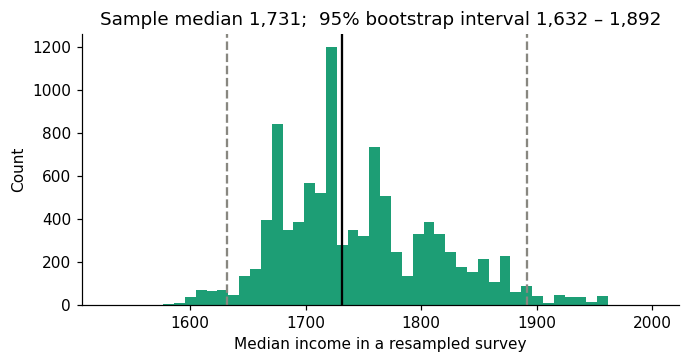

In [8]:
survey = rng.lognormal(mean=7.5, sigma=0.5, size=300)        # 300 incomes, skewed like real incomes

boot_medians = np.array([np.median(rng.choice(survey, size=300, replace=True)) for _ in range(10_000)])
lo, hi = np.percentile(boot_medians, [2.5, 97.5])

plt.hist(boot_medians, bins=50, color=TEAL)
plt.axvline(np.median(survey), color="black"); plt.axvline(lo, color=GRAY, ls="--"); plt.axvline(hi, color=GRAY, ls="--")
plt.xlabel("Median income in a resampled survey"); plt.ylabel("Count")
plt.title(f"Sample median {np.median(survey):,.0f};  95% bootstrap interval {lo:,.0f} – {hi:,.0f}");

## 6.2 Sensitivity analysis: which uncertainty matters most?

At Stop 3 we had two uncertain inputs; real models have dozens. Shake all of them at once, then ask **which input explains most of the variation in the output**. That input is the one worth measuring more precisely. Below, for the referendum, we measure how strongly the result moves with each input (a correlation): the poll error dominates, so better polling would reduce our uncertainty far more than better turnout data.

In [9]:
N = 10_000
poll_error = rng.normal(0, 3, N); turnout_tilt = rng.normal(-1, 1, N)
result = 52 + poll_error + turnout_tilt
for name, inp in [("poll error", poll_error), ("turnout tilt", turnout_tilt)]:
    print(f"{name:13s}: correlation with the result = {np.corrcoef(inp, result)[0, 1]:.2f}")

poll error   : correlation with the result = 0.95
turnout tilt : correlation with the result = 0.33


## 6.3 Markov chain Monte Carlo (MCMC)

In Bayesian statistics the object of interest is a probability distribution over the unknown parameters of a model, given the data. For realistic models that distribution cannot be written down and cannot be sampled directly as we sampled dice and darts. **MCMC** solves this with a random walk through the space of possible parameter values that is steered to linger where the data fit well and hurry past where they fit badly; after enough steps the places visited are a sample from the distribution you wanted. The first such algorithm was published by Metropolis and colleagues in 1953; modern software (Stan, PyMC) makes it routine, and it is the engine behind most contemporary Bayesian analysis.

The cell below is the smallest possible MCMC, included only so you can see that it is, underneath, still "draw random numbers and count". You can skip it.

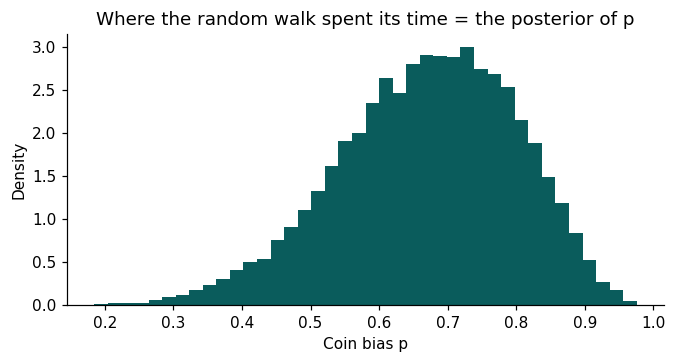

In [10]:
# Tiny Metropolis sampler: find the distribution of a coin's bias p, given 7 heads in 10 flips.
heads, flips = 7, 10
def fit(p):                                   # how well does bias p explain the data? (likelihood)
    return p**heads * (1 - p)**(flips - heads) if 0 < p < 1 else 0

p = 0.5; visited = []
for _ in range(20_000):
    proposal = p + rng.normal(0, 0.1)         # take a small random step
    if rng.random() < fit(proposal) / fit(p): # keep it with probability = how much better it fits
        p = proposal
    visited.append(p)

plt.hist(visited[2000:], bins=40, density=True, color=PURPLE)
plt.xlabel("Coin bias p"); plt.ylabel("Density")
plt.title("Where the random walk spent its time = the posterior of p");

# Take-home message:

1. **Garbage in, gospel out.** A Monte Carlo result is only as good as the distributions fed into it. Ten thousand runs on a wrong assumption give a beautifully smooth histogram that is precisely wrong. State your input assumptions, and test what happens when you change them.
2. **Report the spread, not just the average**: a probability, a median, a 5th to 95th percentile range, a band around a curve.
3. **Use enough runs, and say how many.** A thousand is the usual minimum; more for the tails. If two repetitions of your whole simulation disagree visibly, you need more.
4. **Fix the seed and share the code**, so anyone can reproduce your numbers exactly.
5. **A model is not the world.** Monte Carlo quantifies the uncertainty *inside* a model; it cannot tell you whether the model is right.

# References

* Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum.
* Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics*, 7(1), 1–26.
* Granovetter, M. (1978). Threshold models of collective behavior. *American Journal of Sociology*, 83(6), 1420–1443.
* Metropolis, N. (1987). The beginning of the Monte Carlo method. *Los Alamos Science*, 15, 125–130.
* Metropolis, N., & Ulam, S. (1949). The Monte Carlo method. *Journal of the American Statistical Association*, 44(247), 335–341.
* Metropolis, N., Rosenbluth, A. W., Rosenbluth, M. N., Teller, A. H., & Teller, E. (1953). Equation of state calculations by fast computing machines. *The Journal of Chemical Physics*, 21(6), 1087–1092.
* Schelling, T. C. (1971). Dynamic models of segregation. *Journal of Mathematical Sociology*, 1(2), 143–186.
* Verschuuren, G. M. (2017). *100 Excel Simulations*. Holy Macro! Books.